# BTS Flight Delay Prediction - Data Understanding

This notebook explores the BTS flight dataset to understand its structure,
quality, variables and patterns related to flight delays before preparing
the data for machine learning.

In [7]:
from calendar import TUESDAY, WEDNESDAY, THURSDAY, SATURDAY

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
#loading the dataset
bts_data = pd.read_csv("T_ONTIME_REPORTING.csv")

In [5]:
#getting the top 5 rows
bts_data.head()

,YEAR,MONTH,DAY_OF_MONTH,DAY_OF_WEEK,FL_DATE,OP_UNIQUE_CARRIER,TAIL_NUM,OP_CARRIER_FL_NUM,ORIGIN,ORIGIN_CITY_NAME,DEST,CRS_DEP_TIME,DEP_DEL15,DEP_TIME_BLK,CRS_ARR_TIME,CANCELLED,CANCELLATION_CODE,DIVERTED,CRS_ELAPSED_TIME,DISTANCE
0,2025,1,1,3,1/1/2025 12:00:00 AM,AA,N101NN,164,SFO,"San Francisco, CA",JFK,1030,0.0,1000-1059,1912,0.0,NaN,0.0,342.0,2586.0
1,2025,1,1,3,1/1/2025 12:00:00 AM,AA,N101NN,76,JFK,"New York, NY",SFO,600,0.0,0600-0659,940,0.0,NaN,0.0,400.0,2586.0
2,2025,1,1,3,1/1/2025 12:00:00 AM,AA,N102UW,3244,SAT,"San Antonio, TX",CLT,819,0.0,0800-0859,1206,0.0,NaN,0.0,167.0,1095.0
3,2025,1,1,3,1/1/2025 12:00:00 AM,AA,N103NN,185,JFK,"New York, NY",LAX,2100,0.0,2100-2159,29,0.0,NaN,0.0,389.0,2475.0
4,2025,1,1,3,1/1/2025 12:00:00 AM,AA,N103NN,2455,BOS,"Boston, MA",LAX,801,0.0,0800-0859,1140,0.0,NaN,0.0,399.0,2611.0


Each row represents a scheduled flight. The dataset contains information about the flight date, airline, origin and destination airports, scheduled departure and arrival times, delays, cancellations, diversions, flight duration and distance.

In [6]:
bts_data.shape

(539747, 20)

The dataset contains 539,747 flight records and 20 variables.

In [11]:
bts_data["YEAR"].unique()
bts_data["MONTH"].unique()


array([1])

The dataset contains flights from January 2025.

In [12]:
#understanding the data types of each variable and identify columns that may contain missing values
print (bts_data.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 539747 entries, 0 to 539746
Data columns (total 20 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   YEAR               539747 non-null  int64  
 1   MONTH              539747 non-null  int64  
 2   DAY_OF_MONTH       539747 non-null  int64  
 3   DAY_OF_WEEK        539747 non-null  int64  
 4   FL_DATE            539747 non-null  object 
 5   OP_UNIQUE_CARRIER  539747 non-null  object 
 6   TAIL_NUM           537217 non-null  object 
 7   OP_CARRIER_FL_NUM  539747 non-null  int64  
 8   ORIGIN             539747 non-null  object 
 9   ORIGIN_CITY_NAME   539747 non-null  object 
 10  DEST               539747 non-null  object 
 11  CRS_DEP_TIME       539747 non-null  int64  
 12  DEP_DEL15          523824 non-null  float64
 13  DEP_TIME_BLK       539747 non-null  object 
 14  CRS_ARR_TIME       539747 non-null  int64  
 15  CANCELLED          539747 non-null  float64
 16  CA

The dataset contains 7 integer, 5 float and 8 object variables. Most columns contain values for all 539,747 flights.
However, missing values are present in `TAIL_NUM`, `DEP_DEL15` and `CANCELLATION_CODE`.

`FL_DATE` is currently stored as an object rather than a datetime variable. This will need to be considered during data preparation.

The large number of missing values in `CANCELLATION_CODE` does not necessarily indicate poor data quality, as this variable is
only expected to contain a value when a flight is cancelled.

####  Missing Values

Missing values are checked to identify incomplete variables and determine whether the missing data could affect the analysis or prediction model.

In [13]:
bts_data.isnull().sum()

YEAR                      0
MONTH                     0
DAY_OF_MONTH              0
DAY_OF_WEEK               0
FL_DATE                   0
OP_UNIQUE_CARRIER         0
TAIL_NUM               2530
OP_CARRIER_FL_NUM         0
ORIGIN                    0
ORIGIN_CITY_NAME          0
DEST                      0
CRS_DEP_TIME              0
DEP_DEL15             15923
DEP_TIME_BLK              0
CRS_ARR_TIME              0
CANCELLED                 0
CANCELLATION_CODE    523435
DIVERTED                  0
CRS_ELAPSED_TIME          0
DISTANCE                  0
dtype: int64

In [14]:
# checking the number of cancelled and non-cancelled flights
bts_data["CANCELLED"].value_counts()

CANCELLED
0.0    523435
1.0     16312
Name: count, dtype: int64

#### Cancellation Code

`CANCELLATION_CODE` contains 523,435 missing values. However, the dataset also contains exactly 523,435 non-cancelled flights and 16,312 cancelled flights. This indicates that the missing cancellation codes are expected for flights that were not cancelled, rather than representing a general data quality issue.

In [15]:
# checking whether flights with missing DEP_DEL15 were cancelled
bts_data[bts_data["DEP_DEL15"].isnull()]["CANCELLED"].value_counts()

CANCELLED
1.0    15923
Name: count, dtype: int64

In [16]:
# checking whether flights with missing TAIL_NUM were cancelled
bts_data[bts_data["TAIL_NUM"].isnull()]["CANCELLED"].value_counts()

CANCELLED
1.0    2530
Name: count, dtype: int64

### Missing Values Conclusion

Missing values were found in three columns: `CANCELLATION_CODE`, `DEP_DEL15` and `TAIL_NUM`.

- `CANCELLATION_CODE` is missing for 523,435 flights, which matches the number of non-cancelled flights. These missing values are therefore expected.
- `DEP_DEL15` is missing for 15,923 flights, and all of these flights were cancelled. However, there are 16,312 cancelled flights in total, meaning 389 cancelled flights still have a recorded `DEP_DEL15` value.
- `TAIL_NUM` is missing for 2,530 flights and all of these flights were also cancelled.

Overall, the missing values are strongly related to flight cancellations rather than appearing randomly throughout the dataset.

In [17]:
bts_data.duplicated()

0         False
1         False
2         False
3         False
4         False
          ...  
539742    False
539743    False
539744    False
539745    False
539746    False
Length: 539747, dtype: bool

In [18]:
bts_data.duplicated().sum()

np.int64(0)

No duplicate rows were found in the dataset.

### Numerical Data Quality

Descriptive statistics are examined to identify unusual or potentially invalid values in the numerical variables.

In [19]:
bts_data.describe()

,YEAR,MONTH,DAY_OF_MONTH,DAY_OF_WEEK,OP_CARRIER_FL_NUM,CRS_DEP_TIME,DEP_DEL15,CRS_ARR_TIME,CANCELLED,DIVERTED,CRS_ELAPSED_TIME,DISTANCE
count,539747.0,539747.0,539747.000000,539747.000000,539747.000000,539747.000000,523824.000000,539747.000000,539747.000000,539747.000000,539747.000000,539747.000000
mean,2025.0,1.0,15.831995,4.019748,2492.102685,1315.739317,0.182619,1502.662084,0.030222,0.002160,151.410600,843.208216
std,0.0,0.0,9.036782,1.925782,1669.518460,480.555061,0.386354,502.478468,0.171197,0.046429,73.812226,599.092323
min,2025.0,1.0,1.000000,1.000000,1.000000,5.000000,0.000000,1.000000,0.000000,0.000000,25.000000,31.000000
25%,2025.0,1.0,8.000000,2.000000,1113.000000,905.000000,0.000000,1117.000000,0.000000,0.000000,96.000000,403.000000
50%,2025.0,1.0,16.000000,4.000000,2213.000000,1310.000000,0.000000,1524.000000,0.000000,0.000000,135.000000,701.000000
75%,2025.0,1.0,24.000000,6.000000,3695.000000,1725.000000,0.000000,1924.000000,0.000000,0.000000,183.000000,1083.000000
max,2025.0,1.0,31.000000,7.000000,8819.000000,2359.000000,1.000000,2359.000000,1.000000,1.000000,693.000000,5095.000000


The descriptive statistics do not show any immediately invalid values. `DAY_OF_MONTH` ranges from 1-31 and `DAY_OF_WEEK` from
1-7. The binary variables `DEP_DEL15`, `CANCELLED`, and `DIVERTED` contain values between 0 and 1 as expected.

Flight distance ranges from 31 to 5,095 miles, while scheduled elapsed time ranges from 25 to 693 minutes. These ranges do not
immediately indicate invalid values, although their distributions will be explored further.

`CRS_DEP_TIME` and `CRS_ARR_TIME` represent scheduled clock times in HHMM format, so statistics such as their numerical mean should not be interpreted in the same way as continuous numerical variables.

### Categorical Variables

The categorical variables are explored to understand how many different airlines, airports and departure time blocks are represented in the dataset.

In [20]:
# number of airlines
bts_data["OP_UNIQUE_CARRIER"].nunique()

14

In [21]:
# number of origin airports
bts_data["ORIGIN"].nunique()

329

In [22]:
# number of destination airports
bts_data["DEST"].nunique()

329

In [23]:
# getting the departure time-block categories
bts_data["DEP_TIME_BLK"].unique()

array(['1000-1059', '0600-0659', '0800-0859', '2100-2159', '1100-1159',
       '1200-1259', '0700-0759', '2000-2059', '1700-1759', '1300-1359',
       '2200-2259', '1800-1859', '1600-1659', '2300-2359', '1500-1559',
       '0900-0959', '1900-1959', '1400-1459', '0001-0559'], dtype=object)

The dataset contains 14 airlines and 329 origin and destination airports. Scheduled departure times are grouped into 19
time blocks. Most represent one-hour intervals, while flights scheduled between 00:01 and 05:59 are grouped into a single
`0001-0559` category.

### Target Variable Distribution

`DEP_DEL15` is explored to understand the distribution of the target variable. A value of `0` represents a flight that was not delayed by 15 minutes or more, while `1` represents a flight that was delayed by at least 15 minutes.

In [41]:
# how many flights are delayed versus not delayed
delay_counts = bts_data["DEP_DEL15"].value_counts()
print(delay_counts)

DEP_DEL15
0.0    428164
1.0     95660
Name: count, dtype: int64


In [29]:
# proportions of delayed and not delayed flights
bts_data["DEP_DEL15"].value_counts(normalize=True)

DEP_DEL15
0.0    0.817381
1.0    0.182619
Name: proportion, dtype: float64

Of the flights with a recorded `DEP_DEL15` value, 81.74% were not delayed by 15 minutes or more, while 18.26% were delayed.

This shows that the target variable is imbalanced, with more non-delayed flights than delayed flights. This
should be considered later when evaluating the machine learning model.

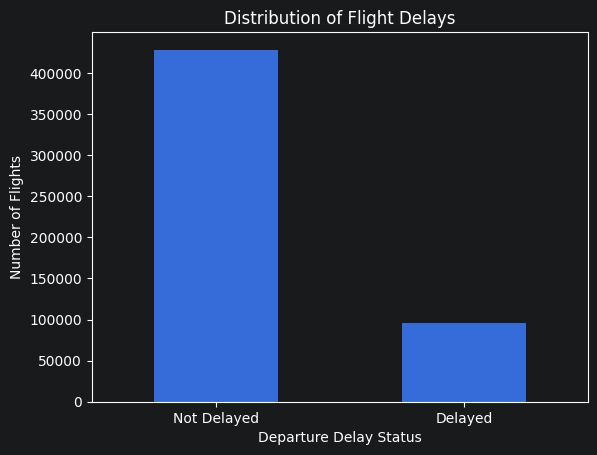

In [44]:
delay_counts.plot(kind="bar")
plt.title("Distribution of Flight Delays")
plt.xlabel("Departure Delay Status")
plt.xticks([0, 1], ["Not Delayed", "Delayed"], rotation=0)
plt.ylabel("Number of Flights")
plt.show()

The bar chart shows a clear difference between the two target classes. Most flights were not delayed by 15 minutes or more,
while delayed flights represent a much smaller proportion of the dataset. This confirms that the target variable is imbalanced.

### Delay Rate by Day of Week

To investigate whether the day of the week is related to flight delays, the proportion of flights delayed by at least 15 minutes is compared across each day of the week.

In [48]:
delay_by_day = bts_data.groupby("DAY_OF_WEEK")["DEP_DEL15"].mean() * 100
print(delay_by_day)

DAY_OF_WEEK
1    21.824366
2    14.944470
3    12.923127
4    16.816548
5    18.925205
6    21.314974
7    21.888851
Name: DEP_DEL15, dtype: float64


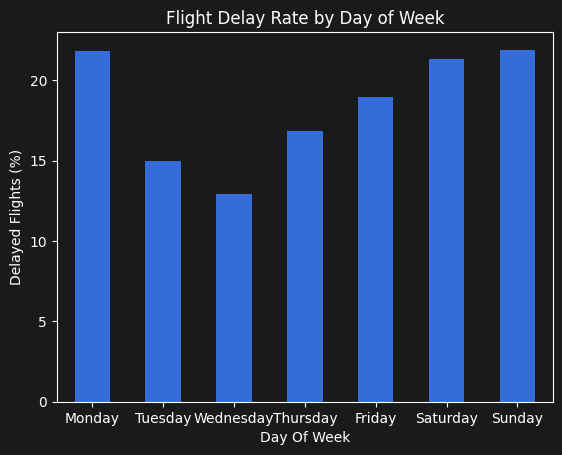

In [49]:
delay_by_day.plot(kind="bar")
plt.title("Flight Delay Rate by Day of Week")
plt.xlabel("Day Of Week")
plt.xticks([0, 1, 2, 3, 4, 5, 6], ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"], rotation=0)
plt.ylabel("Delayed Flights (%)")
plt.show()

The delay rate differs across the days of the week. Wednesday has the lowest delay rate at approximately 12.92%, while Sunday
has the highest at approximately 21.89%. Higher delay rates are also visible on Saturday and Monday.

This suggests that the day of the week may be associated with the likelihood of a flight being delayed.

### Delay Rate by Departure Time

The scheduled departure time is analysed to investigate whether the likelihood of a flight being delayed changes throughout the
day. The delay rate is compared across the different `DEP_TIME_BLK` categories.

In [50]:
delay_by_time = bts_data.groupby("DEP_TIME_BLK")["DEP_DEL15"].mean() * 100
print(delay_by_time)

DEP_TIME_BLK
0001-0559     9.550484
0600-0659     8.092797
0700-0759    10.074627
0800-0859    11.926241
0900-0959    14.484777
1000-1059    16.854841
1100-1159    18.152693
1200-1259    19.649090
1300-1359    20.162907
1400-1459    21.593153
1500-1559    22.170774
1600-1659    22.282837
1700-1759    22.390920
1800-1859    23.192058
1900-1959    24.183181
2000-2059    25.035676
2100-2159    24.409128
2200-2259    22.757270
2300-2359    16.593407
Name: DEP_DEL15, dtype: float64


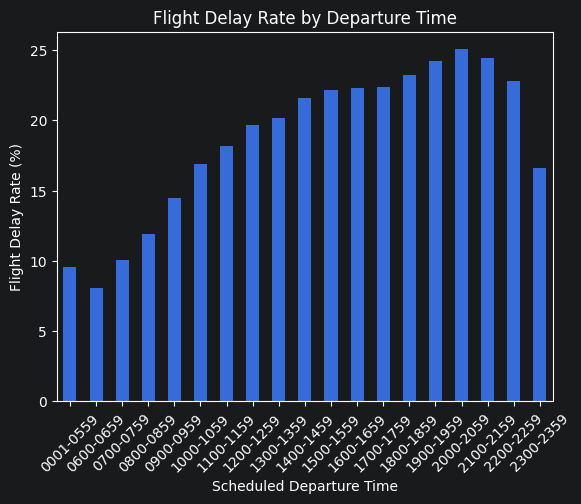

In [51]:
delay_by_time.plot(kind="bar")
plt.title("Flight Delay Rate by Departure Time")
plt.xlabel("Scheduled Departure Time")
plt.ylabel("Flight Delay Rate (%)")
plt.xticks(rotation=45)
plt.show()


The delay rate generally increases as the day progresses. Flights scheduled between 06:00 and 06:59 have the lowest delay rate
at approximately 8.09%, while flights scheduled between 20:00 and 20:59 have the highest delay rate at approximately 25.04%. After 20:00, the delay rate begins to decrease again.

This shows a clear relationship between scheduled departure time and flight delays. The pattern also supports the findings from
the Domain Understanding that delays may accumulate throughout the day. However, this analysis only shows an association and
does not prove that delay propagation is the cause.

### Delay Rate by Airline

Airlines are analysed to investigate whether the likelihood of a flight being delayed differs between carriers. The percentage
of flights delayed by at least 15 minutes is compared across the different airlines in the dataset.

In [53]:
delay_by_airline = bts_data.groupby("OP_UNIQUE_CARRIER")["DEP_DEL15"].mean() * 100
print(delay_by_airline)

OP_UNIQUE_CARRIER
AA    18.795267
AS    16.723321
B6    22.399000
DL    19.655047
F9    23.213578
G4    23.572125
HA    11.432486
MQ    15.790986
NK    18.176464
OH    23.185389
OO    18.712725
UA    16.655712
WN    17.493136
YX    12.266198
Name: DEP_DEL15, dtype: float64


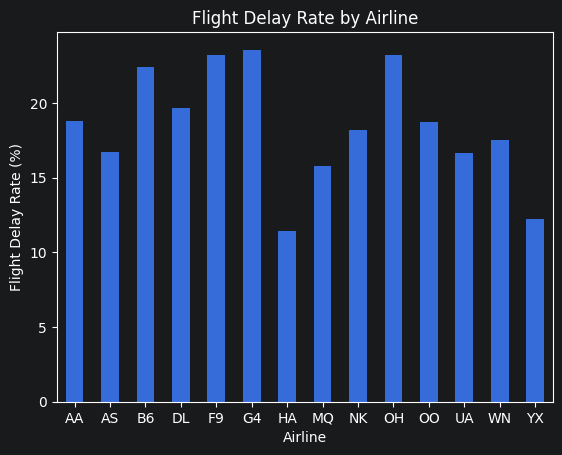

In [54]:
delay_by_airline.plot(kind="bar")
plt.title("Flight Delay Rate by Airline")
plt.xlabel("Airline")
plt.ylabel("Flight Delay Rate (%)")
plt.xticks(rotation=0)
plt.show()

The delay rate differs between airlines. G4 has the highest delay rate at approximately 23.57%, followed closely by F9 and OH
at around 23%. HA has the lowest delay rate at approximately 11.43%, followed by YX at 12.27%.

These differences suggest that airline may be associated with the likelihood of a flight being delayed. However, the analysis
does not show that the airline itself causes the delays, as other factors such as routes, airports and scheduled departure
times may also contribute.

### Delay Rate by Origin Airport

Origin airports are analysed to investigate whether departure delay rates differ between airports. Since the dataset contains
329 origin airports, comparing all airports directly would make the analysis difficult to interpret. Therefore, the busiest
origin airports in the dataset are identified first and their delay rates are compared.

In [58]:
busy_airports = bts_data["ORIGIN"].value_counts().head(10).index
print(busy_airports)

Index(['DFW', 'DEN', 'ATL', 'ORD', 'CLT', 'PHX', 'LAX', 'LAS', 'MCO', 'SEA'], dtype='object', name='ORIGIN')


In [61]:
bts_data["ORIGIN"].isin(busy_airports)

0         False
1         False
2         False
3         False
4         False
          ...  
539742    False
539743    False
539744    False
539745    False
539746    False
Name: ORIGIN, Length: 539747, dtype: bool

In [62]:
bts_data["ORIGIN"].isin(busy_airports).value_counts()

ORIGIN
False    356430
True     183317
Name: count, dtype: int64

In [65]:
busy_airport_data = bts_data[bts_data["ORIGIN"].isin(busy_airports)]
busy_airport_data.shape

(183317, 20)

In [67]:
delay_by_airport = busy_airport_data.groupby("ORIGIN")["DEP_DEL15"].mean() * 100
print(delay_by_airport)

ORIGIN
ATL    22.578655
CLT    17.761240
DEN    23.412617
DFW    23.541137
LAS    18.523508
LAX    13.884077
MCO    21.282390
ORD    19.691773
PHX    14.312820
SEA    16.956632
Name: DEP_DEL15, dtype: float64


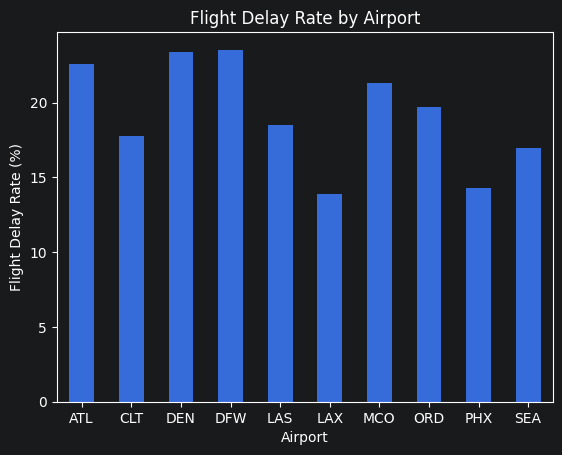

In [68]:
delay_by_airport.plot(kind="bar")
plt.title("Flight Delay Rate by Airport")
plt.xlabel("Airport")
plt.ylabel("Flight Delay Rate (%)")
plt.xticks(rotation=0)
plt.show()

The departure delay rate differs across the 10 busiest origin airports. DFW has the highest delay rate at approximately 23.54%,
while LAX has the lowest at approximately 13.88%. This is a difference of almost 10 percentage points.

This suggests that the origin airport may be associated with the likelihood of a flight being delayed and could therefore be a
useful variable for delay prediction. However, the analysis does not show that the airport itself causes delays, as other
factors such as weather, congestion, airlines and departure times may also contribute.

### Delay Rate by Flight Distance

Flight distance is analysed to investigate whether the likelihood of a departure delay differs depending on the length of the
flight. Since `DISTANCE` is a continuous numerical variable, flights will be grouped into distance ranges so that the delay
rates of shorter and longer flights can be compared.

In [69]:
bts_data["DISTANCE"].describe()

count    539747.000000
mean        843.208216
std         599.092323
min          31.000000
25%         403.000000
50%         701.000000
75%        1083.000000
max        5095.000000
Name: DISTANCE, dtype: float64

In [71]:
distance_groups = pd.qcut(bts_data["DISTANCE"], q=4, labels=["Short", "Medium-Short", "Medium-Long", "Long"])
print(distance_groups)

0                 Long
1                 Long
2                 Long
3                 Long
4                 Long
              ...     
539742    Medium-Short
539743    Medium-Short
539744    Medium-Short
539745    Medium-Short
539746    Medium-Short
Name: DISTANCE, Length: 539747, dtype: category
Categories (4, object): ['Short' < 'Medium-Short' < 'Medium-Long' < 'Long']


In [72]:
distance_groups.value_counts()

DISTANCE
Short           135439
Medium-Long     134908
Long            134756
Medium-Short    134644
Name: count, dtype: int64

In [73]:
delay_by_distance = bts_data.groupby(distance_groups)["DEP_DEL15"].mean() * 100
print(delay_by_distance)

DISTANCE
Short           16.684748
Medium-Short    18.361791
Medium-Long     19.225987
Long            18.769433
Name: DEP_DEL15, dtype: float64


/var/folders/8l/qjj63vqd7d79wqyj2xjj71hm0000gn/T/ipykernel_7698/70366667.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  delay_by_distance = bts_data.groupby(distance_groups)["DEP_DEL15"].mean() * 100


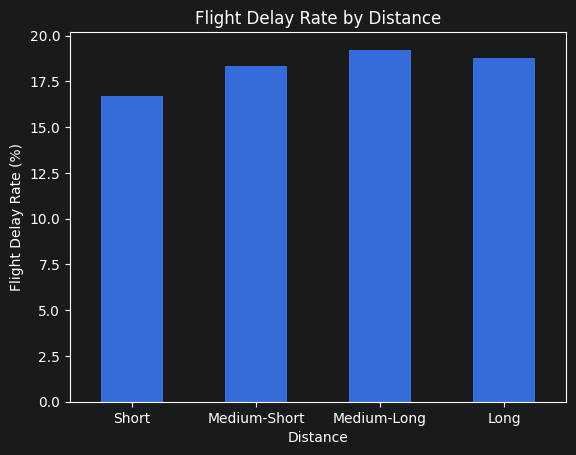

In [74]:
delay_by_distance.plot(kind="bar")
plt.title("Flight Delay Rate by Distance")
plt.xlabel("Distance")
plt.ylabel("Flight Delay Rate (%)")
plt.xticks(rotation=0)
plt.show()

The delay rate varies slightly across the different flight distance groups. Short flights have the lowest delay rate at
approximately 16.68%, while medium-long flights have the highest at approximately 19.23%.

The difference between the highest and lowest delay rates is relatively small and the delay rate does not consistently
increase as flight distance increases. Therefore, flight distance does not appear to have a strong relationship with departure
delays in this dataset.

## Data Understanding Conclusion

The BTS dataset contains 539,747 scheduled flights from January 2025 and 20 variables describing flight schedules, airlines,
airports, cancellations, diversions and flight characteristics.

The data quality analysis showed no duplicate records. Missing values were mainly related to cancelled flights rather than
appearing randomly throughout the dataset. In particular, missing values in `DEP_DEL15` and `TAIL_NUM` occurred only for
cancelled flights, while `CANCELLATION_CODE` was only recorded when applicable.

The target variable `DEP_DEL15` is imbalanced. Approximately 18.26% of flights with a recorded target value were delayed by at
least 15 minutes, compared with 81.74% that were not delayed. This means that accuracy alone may not be sufficient when
evaluating the prediction model.

The exploratory analysis identified several patterns:

- **Day of week:** Delay rates varied across the week, from approximately 12.92% on Wednesday to 21.89% on Sunday.
- **Departure time:** A clear pattern was found throughout the day. Delay rates generally increased from the morning towards
the evening, reaching approximately 25% around 20:00.
- **Airline:** Delay rates differed between carriers, suggesting that airline may be relevant for prediction.
- **Origin airport:** The 10 busiest origin airports showed noticeable differences in delay rates. DFW had approximately 23.54%
delayed flights compared with 13.88% at LAX.
- **Distance:** Only relatively small differences were found between distance groups, suggesting that flight distance has a
weaker relationship with departure delays than the other variables explored.

Overall, scheduled departure time, day of week, airline and origin airport appear to be potentially useful variables for
predicting departure delays. Flight distance may provide additional information but showed a weaker relationship with the
target.

These findings will guide the next Data Preparation step, including handling cancelled flights and missing target values,
converting variables into suitable formats, encoding categorical variables and selecting appropriate features for the machine
learning model.